In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
df = pd.read_csv('heart.csv')

In [45]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [46]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [47]:
df.duplicated().sum()

np.int64(723)

In [48]:
df[df.duplicated()]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
15,34,0,1,118,210,0,1,192,0,0.7,2,0,2,1
31,50,0,1,120,244,0,1,162,0,1.1,2,0,2,1
43,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
55,55,1,0,140,217,0,1,111,1,5.6,0,0,3,0
61,66,0,2,146,278,0,0,152,0,0.0,1,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [49]:
df = df.drop_duplicates()

In [50]:
df.duplicated().sum()

np.int64(0)

<Axes: >

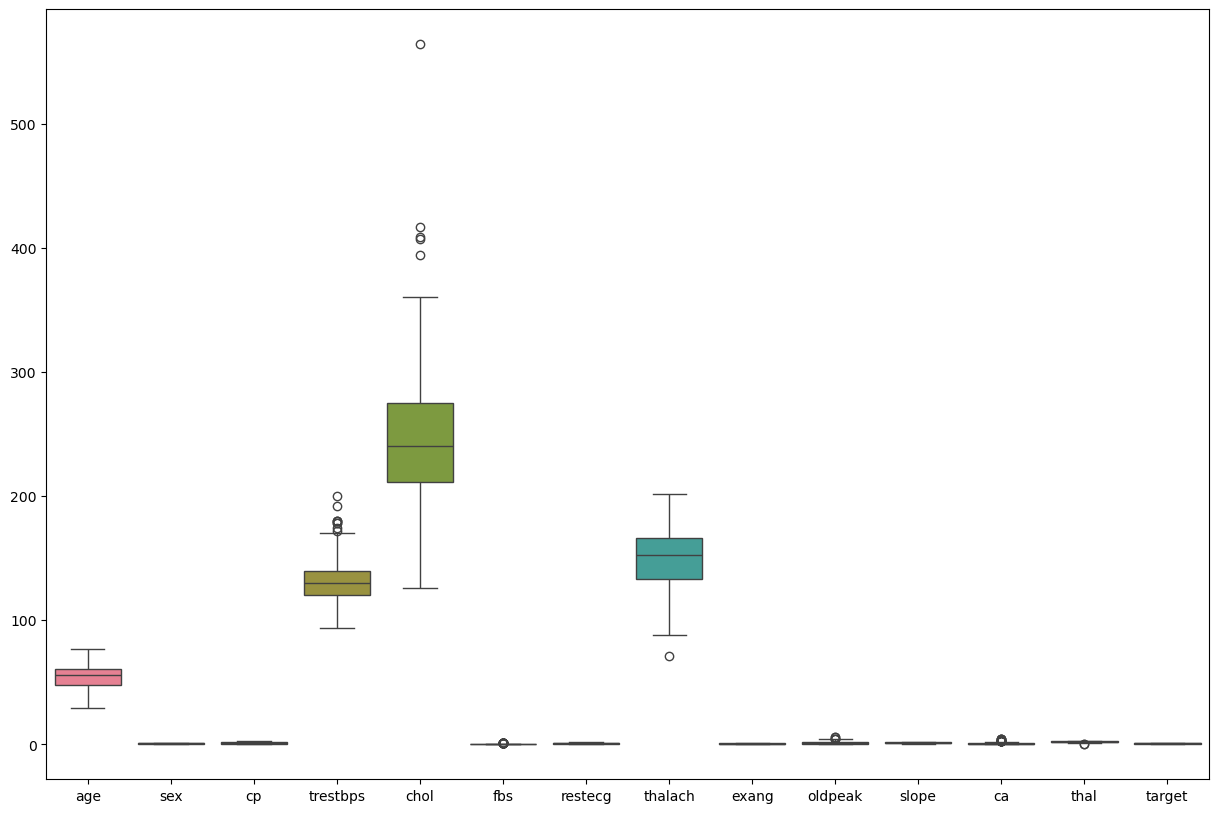

In [51]:
plt.figure(figsize=(15, 10))
sns.boxplot(df)


In [52]:
outlier_counts = {}

for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outlier_counts[col] = ((df[col] < lower) | (df[col] > upper)).sum()

outlier_df = pd.DataFrame(
    list(outlier_counts.items()),
    columns=['Column', 'Outlier Count']
)

outlier_df

,Column,Outlier Count
0,age,0
1,sex,0
2,cp,0
3,trestbps,9
4,chol,5
5,fbs,45
6,restecg,0
7,thalach,1
8,exang,0
9,oldpeak,5


In [53]:
outlier_df['Outlier Count'].sum()

np.int64(91)

<Axes: >

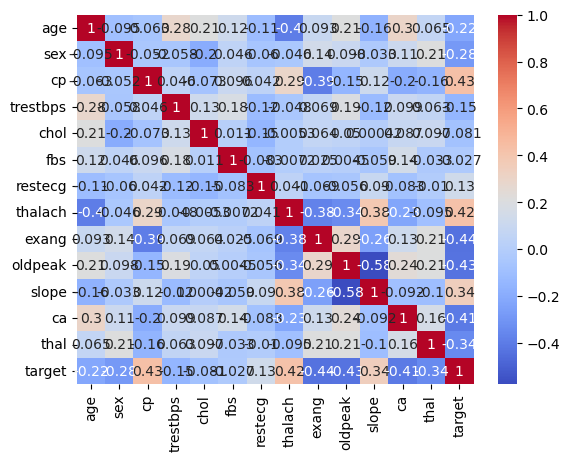

In [54]:
corr = df.corr()
sns.heatmap(corr, annot = True, cmap = 'coolwarm')

این دیتاست مربوط به اطلاعات ۱۰۲۵ بیمار و عوامل مرتبط با بیماری قلبی است‌.
۱۴ ستون شامل اطلاعاتی مثل سن، جنسیت، فشار خون در حالت استراحت، درد قفسه سینه ناشی از ورزش و... است.
همچنین target مشخص می‌کند که فرد بیماری قلبی دارد یا خیر.
همچنین تمام داده های این دیتاست به صورت عددی ثبت و کد گذاری شده اند

همچنین وجود داده‌های پرت در این دیتاست می‌تواند بر شاخص‌های آماری مانند میانگین و انحراف معیار تأثیر گذاشته و باعث ایجاد سوگیری در تحلیل داده‌ها شود.

برای شناسایی داده‌های تکراری از تابع duplicated() در کتابخانه Pandas استفاده شد. در صورت وجود ردیف‌های تکراری، این داده‌ها می‌توانند باعث ایجاد سوگیری در نتایج تحلیل و کاهش اعتبار ارزیابی مدل شوند.

In [55]:
df = df[['age','chol','fbs','thalach','ca','target']]

In [56]:
df

,age,chol,fbs,thalach,ca,target
0,52,212,0,168,2,0
1,53,203,1,155,0,0
2,70,174,0,125,0,0
3,61,203,0,161,1,0
4,62,294,1,106,3,0
...,...,...,...,...,...,...
723,68,211,0,115,0,1
733,44,141,0,175,0,1
739,52,255,0,161,1,0
843,59,273,0,125,0,0


In [57]:
df['age'].describe()

count    302.00000
mean      54.42053
std        9.04797
min       29.00000
25%       48.00000
50%       55.50000
75%       61.00000
max       77.00000
Name: age, dtype: float64

<Axes: xlabel='age', ylabel='Count'>

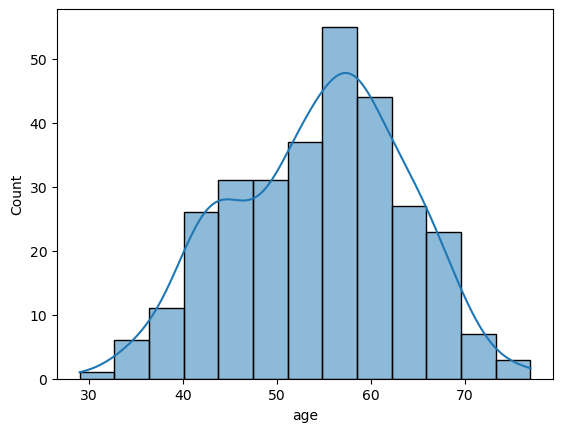

In [58]:
sns.histplot(df['age'],kde = True)

<Axes: ylabel='age'>

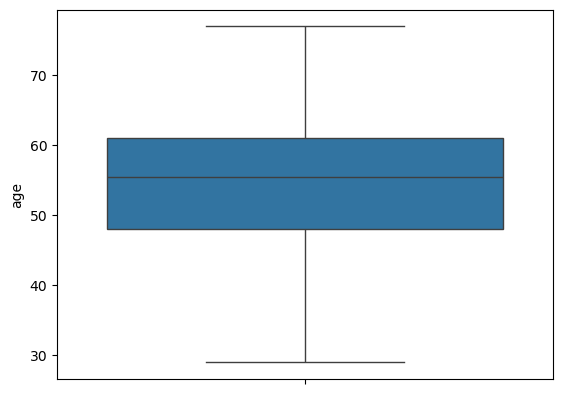

In [59]:
sns.boxplot(df['age'])

ستون age:
نمودار توزیع داده‌های ستون age نشان می‌دهد که توزیع این متغیر نرمال نیست و حالت دو‌قله‌ای Bimodal دارد. این موضوع می‌تواند نشان‌دهنده وجود دو گروه سنی متفاوت در داده‌ها باشد. همچنین، بر اساس نمودار Boxplot، داده پرت قابل‌توجهی در این ستون مشاهده نشد.


<Axes: xlabel='chol', ylabel='Count'>

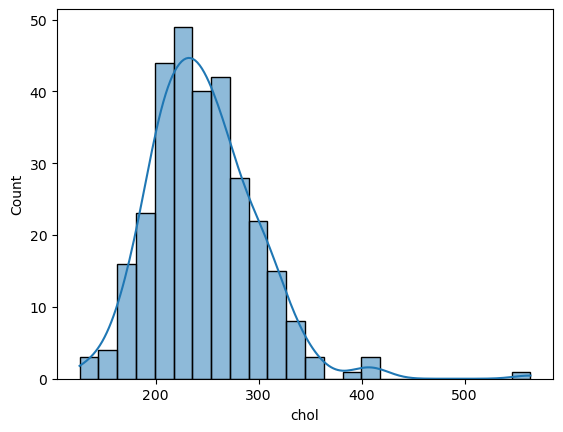

In [60]:
sns.histplot(df['chol'],kde = True)

<Axes: xlabel='chol_log', ylabel='Count'>

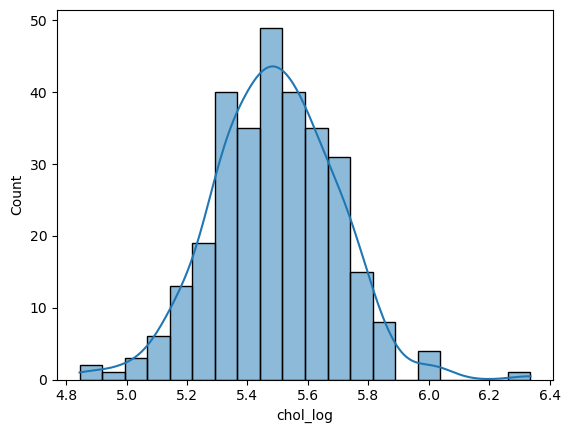

In [61]:
df['chol_log'] = np.log1p(df['chol'])
sns.histplot(df['chol_log'], kde = True)

<Axes: ylabel='chol'>

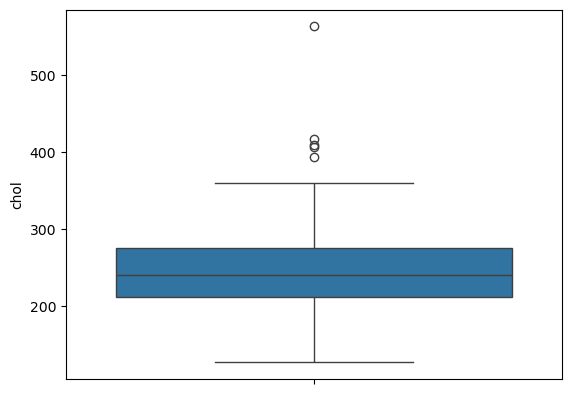

In [62]:
sns.boxplot(df['chol'])

ستون chol:
با توجه به نمودار توزیع ستون chol، توزیع این متغیر نرمال نیست و چوله به راست (Right-Skewed) است. همچنین، با توجه به نمودار توزیع و Boxplot، در این ستون تعدادی داده پرت (Outlier) مشاهده می‌شود.

In [63]:
df['fbs'].value_counts()

fbs
0    257
1     45
Name: count, dtype: int64

<Axes: xlabel='fbs', ylabel='count'>

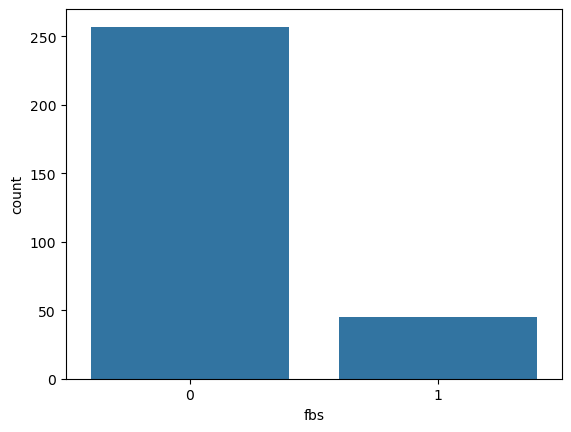

In [64]:
sns.countplot(x = df['fbs'])

ستون fbs (قند خون ناشتا):
با توجه به نمودار، حدود ۲۵۷ نفر دارای قند خون ناشتا کمتر یا مساوی ۱۲۰ mg/dl هستند و حدود ۴۵ نفر دارای قند خون ناشتا بیشتر از ۱۲۰ mg/dl هستند. بنابراین، تعداد افرادی که قند خون ناشتا بالاتر از ۱۲۰ دارند، نسبت به گروه دیگر کمتر است.

<Axes: xlabel='thalach', ylabel='Count'>

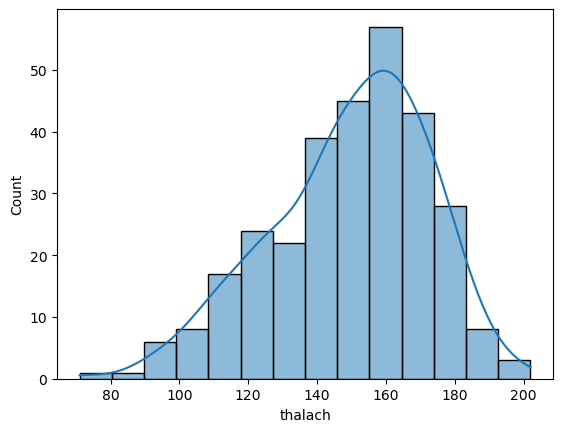

In [65]:
sns.histplot(df['thalach'], kde = True)

<Axes: ylabel='thalach'>

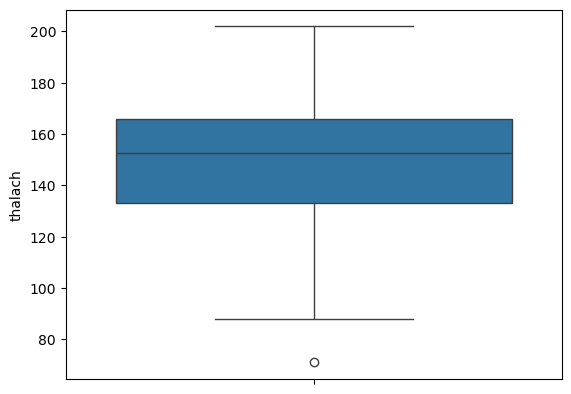

In [66]:
sns.boxplot(df['thalach'])

ستون thalach (حداکثر ضربان قلب):
با توجه به نمودار توزیع ستون thalach، توزیع این متغیر نرمال نیست و تقریباً چوله به چپ (Left-Skewed) است. همچنین، با توجه به نمودار Boxplot، تعداد کمی داده پرت (Outlier) در این ستون مشاهده می‌شود.

In [67]:
df['ca'].info()

<class 'pandas.core.series.Series'>
Index: 302 entries, 0 to 878
Series name: ca
Non-Null Count  Dtype
--------------  -----
302 non-null    int64
dtypes: int64(1)
memory usage: 4.7 KB


In [68]:
df['ca'].value_counts()

ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

<Axes: xlabel='ca', ylabel='count'>

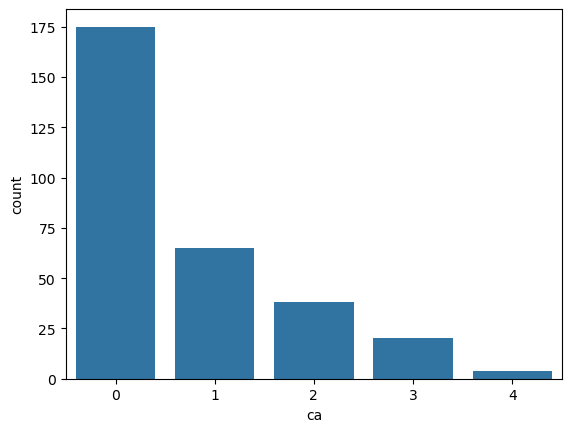

In [69]:
sns.countplot(x = df['ca'])

ستون ca (تعداد عروق اصلی):
این ستون تعداد عروق اصلی قلبی مشاهده‌شده را نشان می‌دهد. با توجه به نمودار، تعداد افرادی که دارای ۱، ۲، ۳ و ۴ عروق اصلی هستند مشخص شده است.

In [70]:
df['target'].value_counts()

target
1    164
0    138
Name: count, dtype: int64

<Axes: xlabel='target', ylabel='count'>

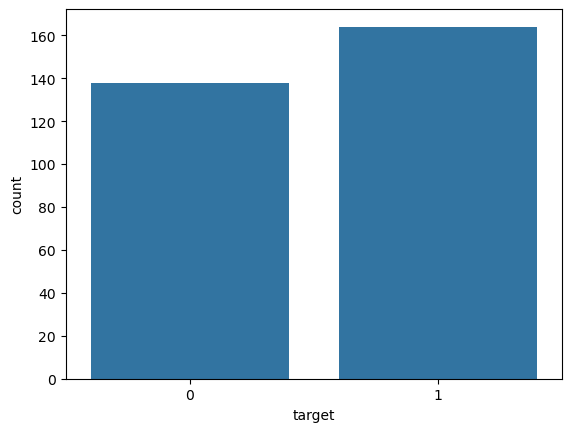

In [71]:
sns.countplot(x = 'target', data = df)

ستون target (وجود بیماری قلبی):
این ستون نشان‌دهنده وجود یا عدم وجود بیماری قلبی در افراد است. با توجه به نمودار، حدود ۱۶۴ نفر دارای بیماری قلبی و حدود ۱۳۸ نفر فاقد بیماری قلبی هستند.

<Axes: >

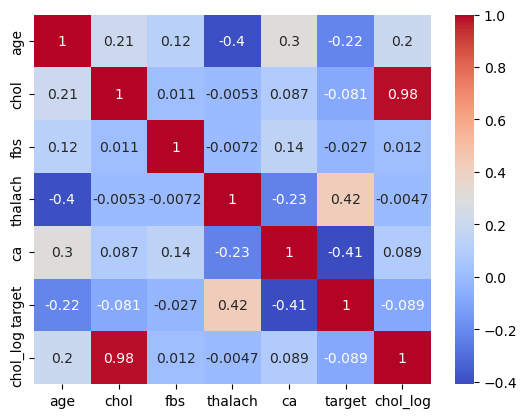

In [72]:
corr = df.corr()
sns.heatmap(corr, annot = True, cmap = 'coolwarm')

<Axes: xlabel='target', ylabel='age'>

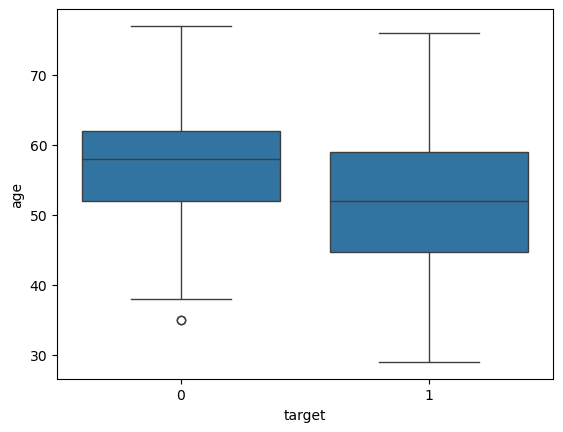

In [73]:
sns.boxplot(x = 'target', y = 'age', data = df)

In [74]:
df.groupby('target')['age'].mean()

target
0    56.601449
1    52.585366
Name: age, dtype: float64

<Axes: xlabel='age', ylabel='Density'>

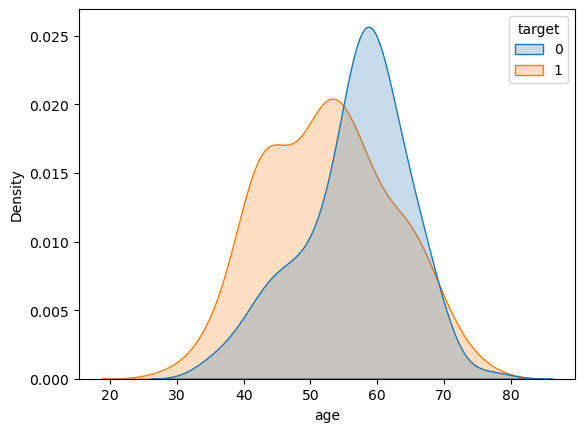

In [75]:
sns.kdeplot(data = df, x = 'age',hue = 'target', fill = True)

سن و هدف :
با مقایسه سن افراد در دو گروه دارای بیماری قلبی و فاقد بیماری قلبی مشاهده می‌شود که هم میانگین و هم میانه سن افراد مبتلا به بیماری قلبی کمتر از افراد فاقد بیماری قلبی است. همچنین، پراکندگی سن در گروه مبتلا بیشتر بوده و در گروه فاقد بیماری قلبی چند داده پرت مشاهده می‌شود.


<Axes: xlabel='target', ylabel='chol'>

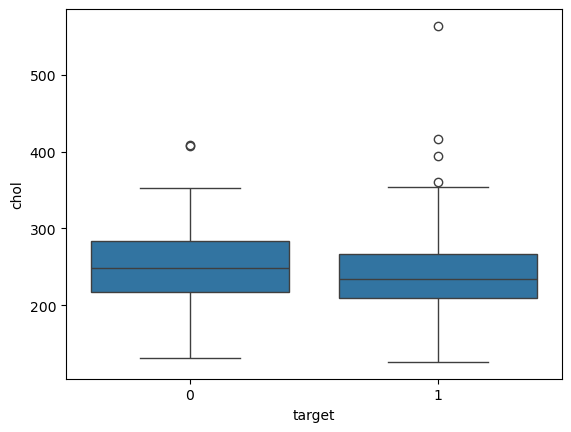

In [76]:
sns.boxplot(x = 'target', y = 'chol', data = df)

کلسترول (chol) و هدف:
با مقایسه میزان کلسترول در دو گروه مشاهده می‌شود که میانه کلسترول افراد دارای بیماری قلبی کمتر از افراد فاقد بیماری قلبی است. همچنین، در گروه افراد دارای بیماری قلبی، پراکندگی مقادیر کلسترول تقریبا بیشتر بوده و داده‌های پرت بیشتری نیز مشاهده می‌شود.


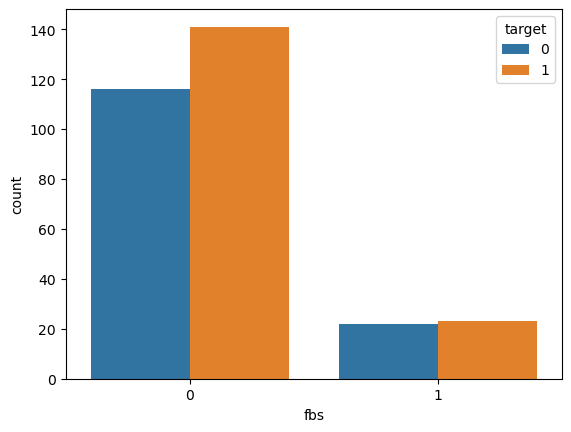

In [77]:
sns.countplot(data = df, x = 'fbs', hue = 'target')
plt.show()

In [78]:
pd.crosstab(df['fbs'], df['target'], normalize = 'index') * 100

target,0,1
fbs,,
0,45.136187,54.863813
1,48.888889,51.111111


قند خون ناشتا (fbs) و هدف:
با بررسی رابطه بین قند خون ناشتا و بیماری قلبی مشاهده می‌شود که در هر دو گروه افراد با fbs=0 و fbs=1 تعداد افراد دارای بیماری قلبی بیشتر از افراد فاقد بیماری قلبی است. همچنین، تعداد افراد دارای بیماری قلبی در گروه fbs=0 بیشتر از گروه fbs=1 است.


<Axes: xlabel='target', ylabel='thalach'>

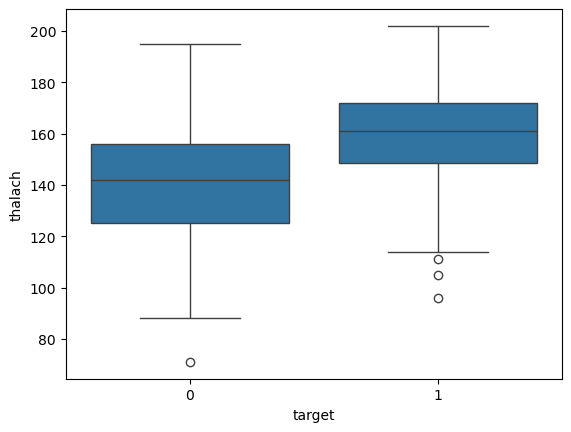

In [79]:
sns.boxplot(x = 'target', y = 'thalach', data = df)

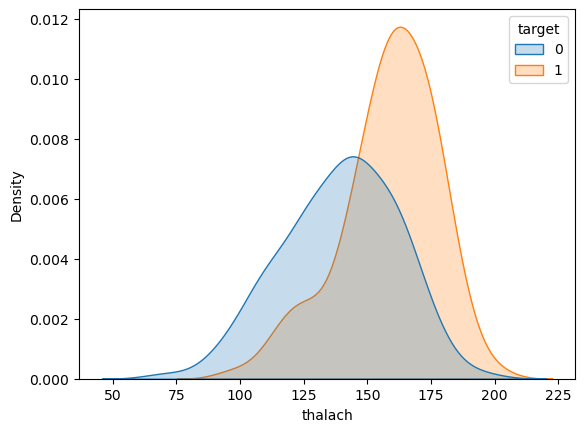

In [80]:
sns.kdeplot(data = df ,x = 'thalach' ,hue = 'target' ,fill = True)
plt.show()

حداکثر ضربان قلب (thalach) و هدف:
با مقایسه دو گروه مشاهده می‌شود که میانه مقدار thalach در افراد دارای بیماری قلبی بیشتر از افراد فاقد بیماری قلبی است. همچنین، پراکندگی مقادیر thalach در گروه افراد مبتلا کمتر بوده و داده‌های پرت بیشتری نیز در این گروه مشاهده می‌شود.


<Axes: xlabel='ca', ylabel='count'>

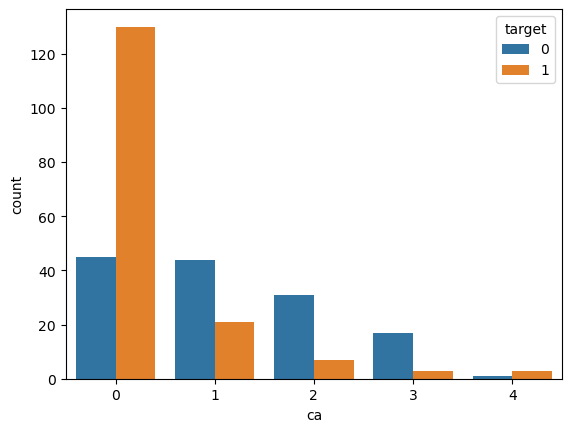

In [81]:
sns.countplot(x = 'ca', hue = 'target', data = df)

In [82]:
pd.crosstab(df['ca'], df['target'], normalize = 'index') * 100

target,0,1
ca,,
0,25.714286,74.285714
1,67.692308,32.307692
2,81.578947,18.421053
3,85.000000,15.000000
4,25.000000,75.000000


تعداد عروق اصلی (ca) و هدف:
با بررسی رابطه بین تعداد عروق اصلی و بیماری قلبی مشاهده می‌شود که در مقادیر ca=1 و ca=4 درصد افراد مبتلا به بیماری قلبی بیشتر است، در حالی که در مقادیر ca=2 و ca=3 درصد افراد مبتلا کمتر است. همچنین، تعداد افراد دارای ca=0 که بیماری قلبی دارند بیشتر از سایر حالت‌هاست. به‌طور کلی، تعداد افرادی که تعداد عروق اصلی آن‌ها صفر است، بیشتر از سایر مقادیر ca مشاهده می‌شود.


.

1. افرادی که حداکثر ضربان قلب در هنگام ورزش بالاتری دارند، در این دیتاست بیشتر با بیماری قلبی مشاهده می‌شوند.

2. افراد دارای بیماری قلبی، در این دیتاست معمولاً سن پایین‌تری نسبت به افراد فاقد بیماری قلبی دارند.

3. افراد دارای بیماری قلبی، در این دیتاست معمولاً کلسترول پایین‌تری نسبت به افراد فاقد بیماری قلبی دارند.

4. در افرادی که تعداد عروق اصلی آن‌ها ۱ یا ۴ است، درصد افراد مبتلا به بیماری قلبی بیشتر مشاهده می‌شود.

5. در هر دو گروه افراد با قند خون ناشتا ۰ و ۱، تعداد افراد مبتلا به بیماری قلبی بیشتر است؛ با این حال، تعداد افراد مبتلا در گروه "fbs=0" بیشتر است.


به‌طور کلی، در این دیتاست ارتباط بسیار قوی و قطعی بین ویژگی‌ها و متغیر هدف مشاهده نمی‌شود. برای مثال، اگرچه در این دیتاست افراد مبتلا به بیماری قلبی به‌طور میانگین سن پایین‌تری نسبت به افراد فاقد بیماری داشته‌اند، اما نمی‌توان نتیجه گرفت که افراد جوان‌تر در دنیای واقعی احتمال بیشتری برای ابتلا به بیماری قلبی دارند. این نتیجه فقط بیانگر الگویی است که در همین دیتاست مشاهده شده و برای تعمیم آن به جامعه واقعی، به داده‌های بیشتر و بررسی‌های آماری دقیق‌تر نیاز است.
